# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import CactusAerialPhotosDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/cactus_aerial_photos/training_set/",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = CactusAerialPhotosDataset(dataset_config)

## Show images from the dataset

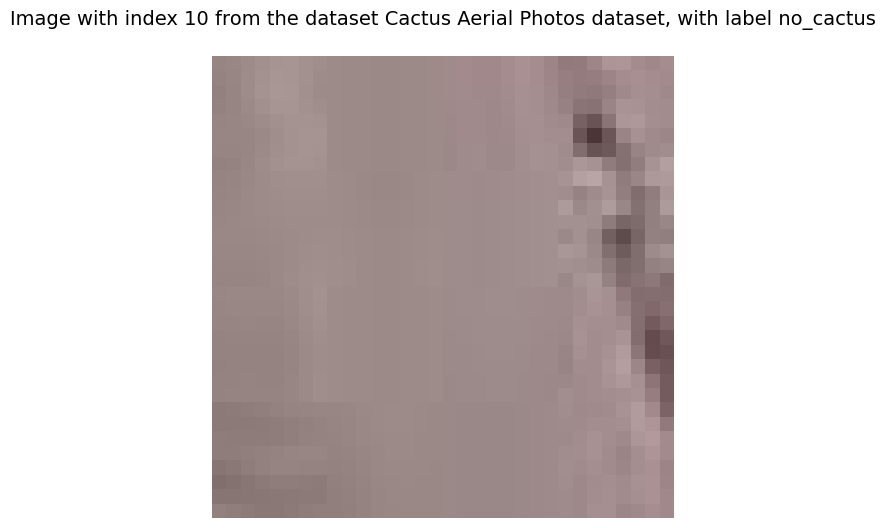

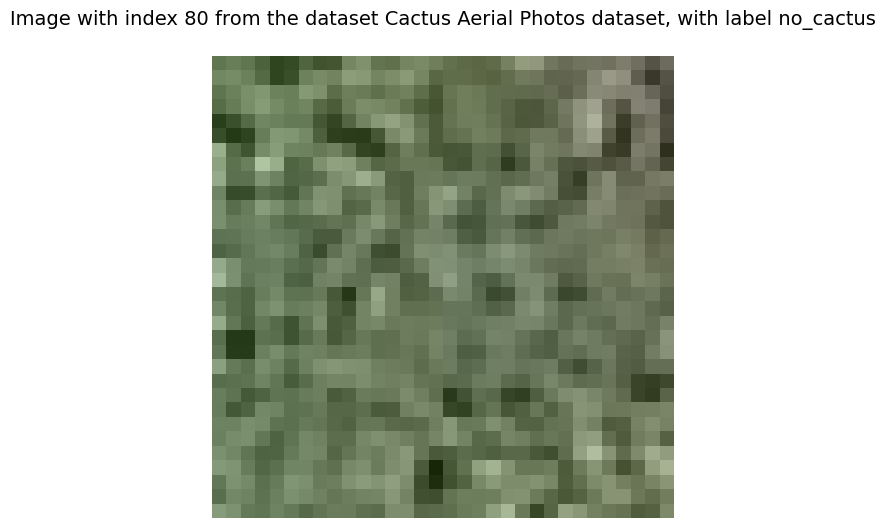

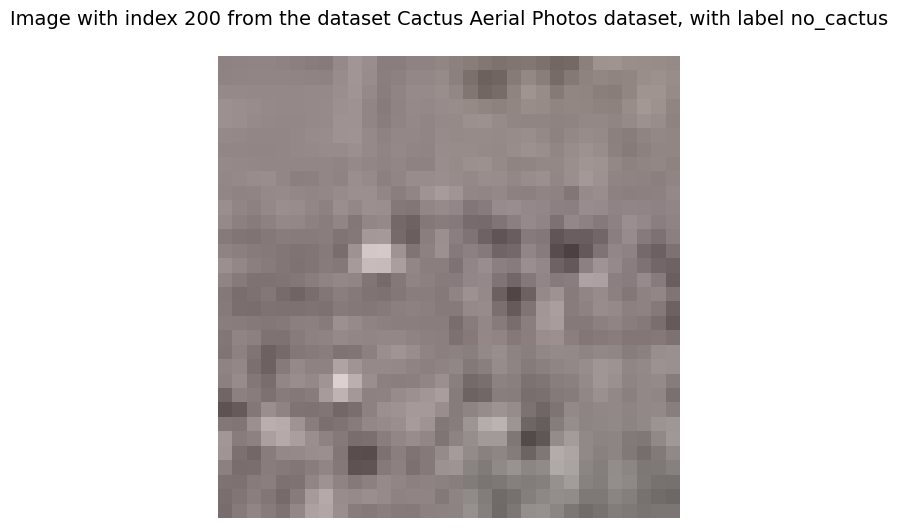

In [156]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

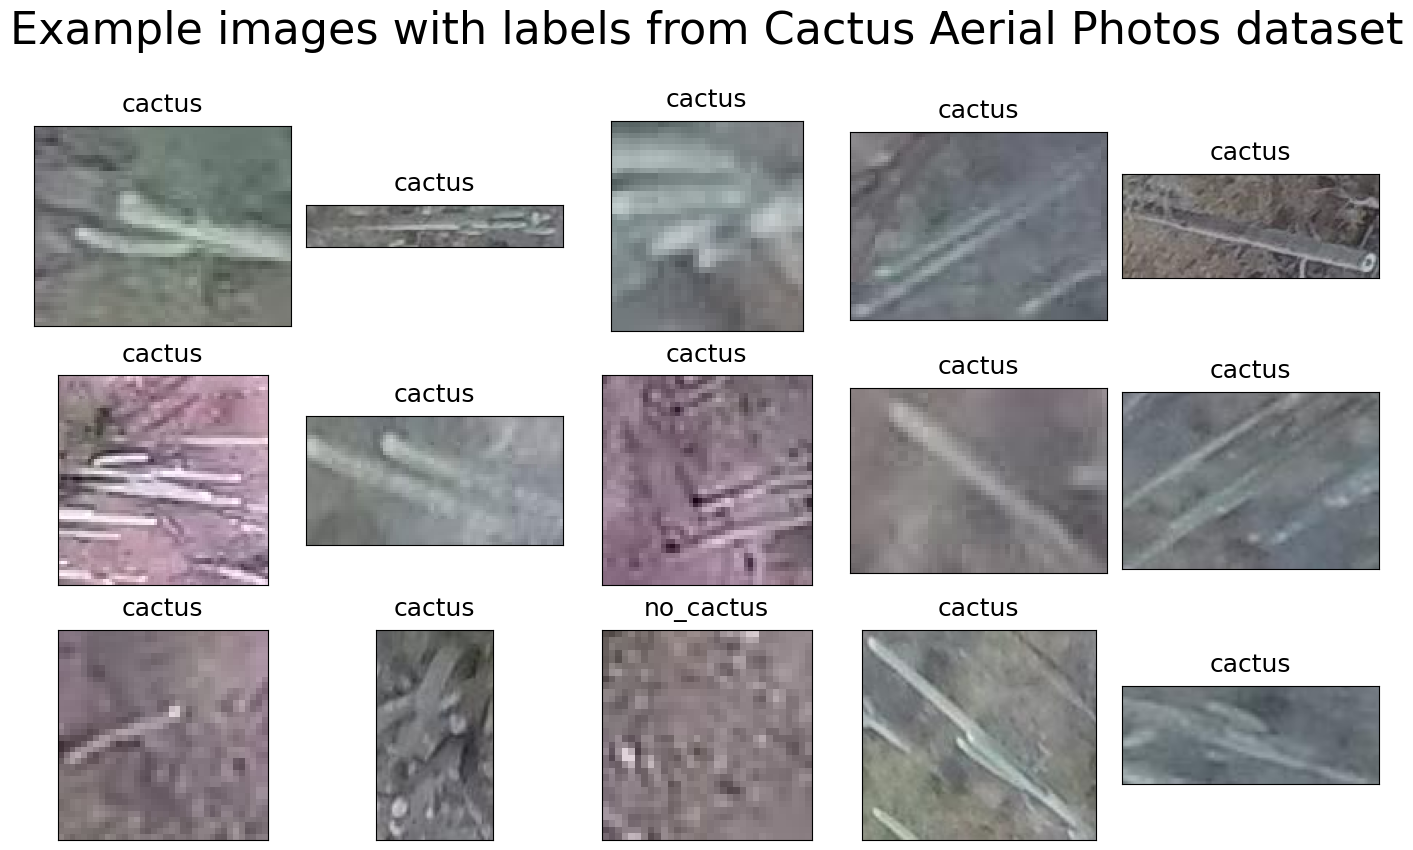

In [19]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [157]:
dataset.data_distribution_table()

,Label,Count
0,cactus,42731
1,no_cactus,4364


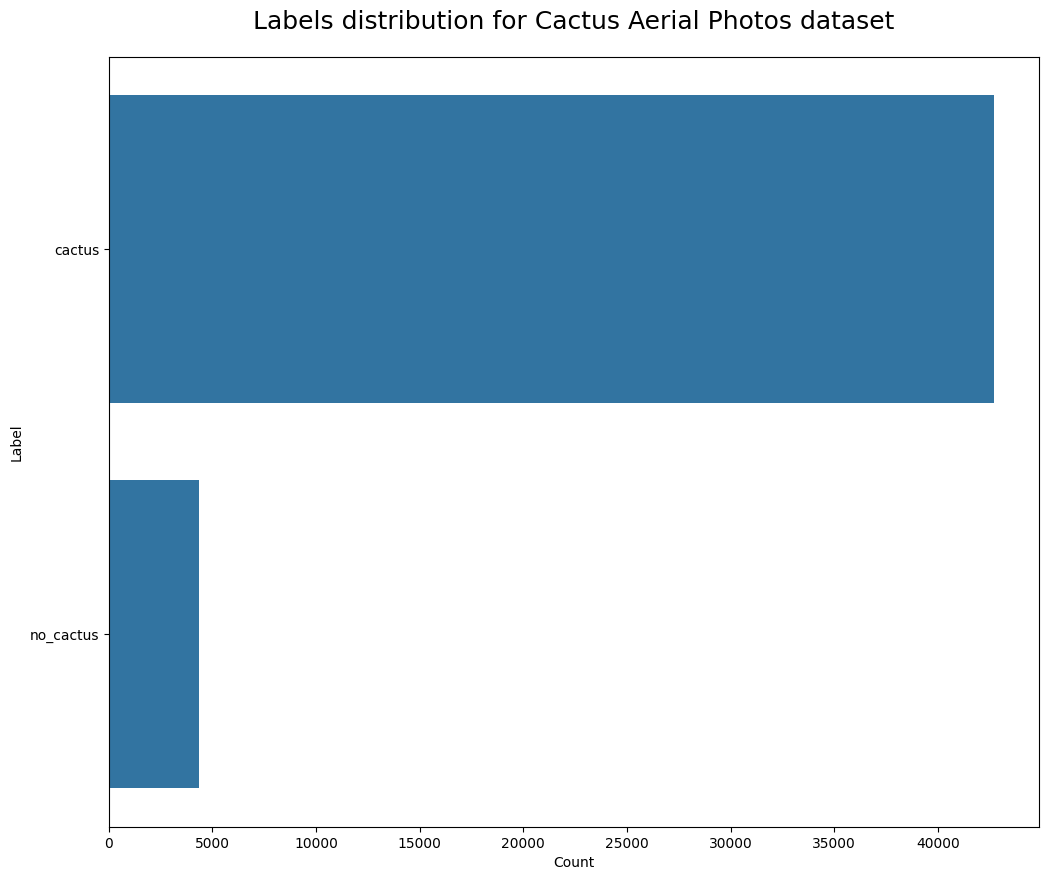

In [158]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/cactus_aerial_photos/training_set/",
}

train_dataset = CactusAerialPhotosDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/cactus_aerial_photos/test_set/",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = CactusAerialPhotosDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(47095, 4000)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/cactus_aerial_photos/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-14 09:51:48,037 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-14 09:51:48,168 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [8]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-14 09:51:49,931 INFO Starting training.
training: 100%|██████████| 1472/1472 [13:29<00:00,  1.82it/s]
2025-05-14 10:05:19,899 INFO epoch: 1, time: 809, loss:  0.04744
testing on train set: 100%|██████████| 1472/1472 [04:56<00:00,  4.96it/s]
2025-05-14 10:10:18,574 INFO Accuracy:0.9930565877481686, Precision Micro:0.9930565877481686, Precision Macro:0.9844475281985947, Precision Weighted:0.9930097229710887, Precision per Class:[0.97393754 0.99495751], Recall Micro:0.9930565877481686, Recall Macro:0.973953239459496, Recall Weighted:0.9930565877481686, Recall per Class:[0.95050412 0.99740235], F1_score Micro:0.9930565877481681, F1_score Macro:0.9791282981634055, F1_score Weighted:0.9930185738573799, F1_score per Class:[0.96207816 0.99617843]
testing on validation set: 100%|██████████| 125/125 [00:24<00:00,  5.15it/s]
2025-05-14 10:10:42,844 INFO Accuracy:0.99025, Precision Micro:0.99025, Precision Macro:0.9897645117814918, Precision Weighted:0.9902418846610475, Precision per Class

0.01810856334957568

## Predictions

2025-05-14 13:09:12,934 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/cactus_aerial_photos/checkpoint.pth.tar
2025-05-14 13:09:13,147 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/cactus_aerial_photos/checkpoint.pth.tar at epoch 11


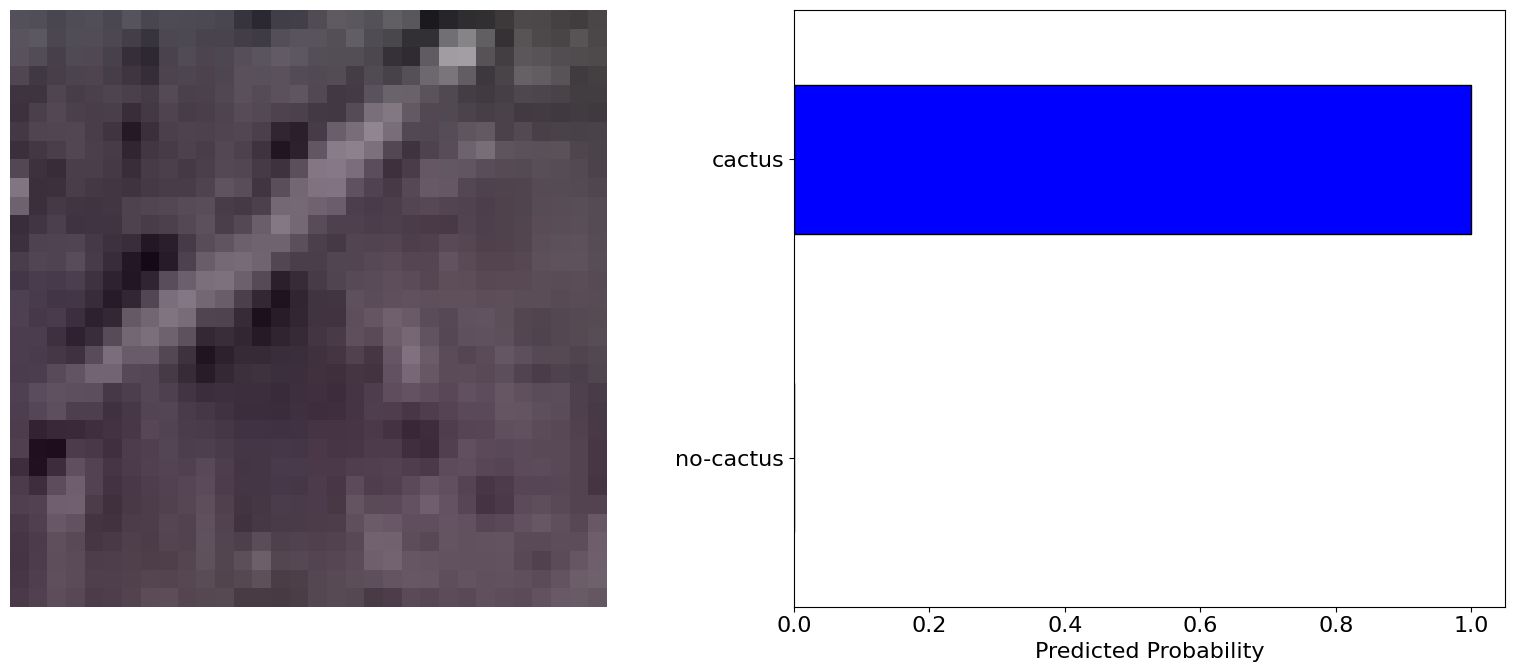

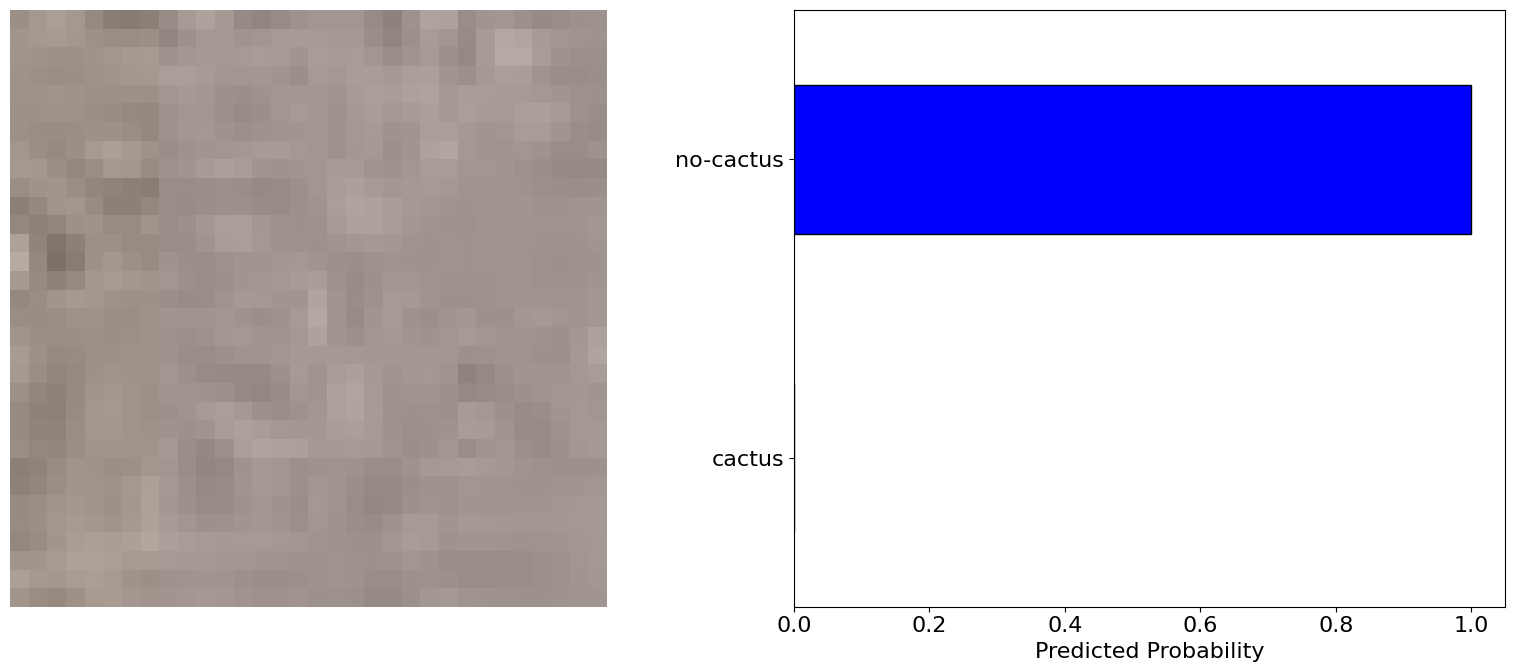

In [ ]:
labels = ["no-cactus","cactus"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/cactus_aerial_photos/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/cactus_aerial_photos/test_set/cactus/cactus_0275_39.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/cactus_aerial_photos/test_set/no_cactus/Sinplanta.4371.jpg')
fig = model.predict_image(image, labels, transform)